In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import unicodedata
import re
import numpy as np

In [30]:
df = pd.read_csv(
    '/media/fabian/INFO/Universidad externado/Bayesiana/Proyecto/data/delitos_unificados.csv')
df

,DELITO,MUNICIPIO,ARMAS MEDIOS,FECHA HECHO,GENERO,AGRUPA EDAD PERSONA,CANTIDAD
0,abigeato,POPAYÁN (CT),NO REPORTADO,2010-01-03,MASCULINO,ADULTOS,1.0
1,abigeato,PEREIRA (CT),NO REPORTADO,2010-01-04,MASCULINO,ADULTOS,1.0
2,abigeato,VILLAVICENCIO (CT),NO REPORTADO,2010-01-06,MASCULINO,ADULTOS,1.0
3,abigeato,POPAYÁN (CT),NO REPORTADO,2010-01-07,MASCULINO,ADULTOS,1.0
4,abigeato,VALLEDUPAR (CT),ARMA BLANCA / CORTOPUNZANTE,2010-01-08,MASCULINO,ADULTOS,2.0
...,...,...,...,...,...,...,...
1873991,amenazas_2020,PUERTO CARREÑO (CT),SIN EMPLEO DE ARMAS,2020-01-06,MASCULINO,ADULTOS,1.0
1873992,amenazas_2020,PUERTO CARREÑO (CT),SIN EMPLEO DE ARMAS,2020-05-22,FEMENINO,ADULTOS,1.0
1873993,amenazas_2020,PUERTO CARREÑO (CT),SIN EMPLEO DE ARMAS,2020-07-07,MASCULINO,ADULTOS,1.0
1873994,amenazas_2020,PUERTO CARREÑO (CT),SIN EMPLEO DE ARMAS,2020-10-22,MASCULINO,ADULTOS,1.0


In [31]:
df.dtypes

DELITO                  object
MUNICIPIO               object
ARMAS MEDIOS            object
FECHA HECHO             object
GENERO                  object
AGRUPA EDAD PERSONA     object
CANTIDAD               float64
dtype: object

In [32]:
#df = df[df['MUNICIPIO'] == 'BOGOTÁ D.C. (CT)']
df['FECHA HECHO'] = pd.to_datetime(df['FECHA HECHO'])
#df.set_index('FECHA HECHO', inplace=True)

## Delito

In [33]:
def limpiar_delito(valor):
    # 1. Poner todo en minúsculas
    valor = valor.lower()
    
    # 2. Reemplazar espacios con guiones bajos
    valor = valor.replace(" ", "_")
    
    # 3. Eliminar números (años, etc.) y paréntesis
    valor = re.sub(r'[\d()]+', '', valor)
    
    # 4. Eliminar guiones bajos duplicados (por si quedaron "__")
    valor = re.sub(r'_+', '_', valor)
    
    # 5. Quitar guiones bajos al inicio o final (si quedaron)
    valor = valor.strip('_')
    
    return valor

# Aplicar la función a la columna
df['DELITO'] = df['DELITO'].apply(limpiar_delito)
df['MUNICIPIO'].value_counts()

MUNICIPIO
BOGOTÁ D.C. (CT)              422180
CALI (CT)                     188838
MEDELLÍN (CT)                 166707
BARRANQUILLA (CT)             100118
BUCARAMANGA (CT)               79131
VILLAVICENCIO (CT)             77383
CARTAGENA (CT)                 68074
IBAGUÉ (CT)                    67603
PASTO (CT)                     66731
CÚCUTA (CT)                    61652
PEREIRA (CT)                   60529
NEIVA (CT)                     55888
POPAYÁN (CT)                   47587
SANTA MARTA (CT)               46666
MANIZALES (CT)                 40895
VALLEDUPAR (CT)                40163
MONTERÍA (CT)                  38929
ARMENIA (CT)                   35622
SINCELEJO (CT)                 35166
FLORENCIA (CT)                 28692
TUNJA (CT)                     27963
YOPAL (CT)                     23462
RIOHACHA (CT)                  20694
QUIBDÓ (CT)                    17589
ARAUCA (CT)                    14957
SAN ANDRÉS (CT)                11084
LETICIA (CT)                

In [34]:
df['MUNICIPIO'] = df['MUNICIPIO'].str.replace(r'\s*\(CT\)', '', regex=True)
df['MUNICIPIO'].value_counts()

MUNICIPIO
BOGOTÁ D.C.              422180
CALI                     188838
MEDELLÍN                 166707
BARRANQUILLA             100118
BUCARAMANGA               79131
VILLAVICENCIO             77383
CARTAGENA                 68074
IBAGUÉ                    67603
PASTO                     66731
CÚCUTA                    61652
PEREIRA                   60529
NEIVA                     55888
POPAYÁN                   47587
SANTA MARTA               46666
MANIZALES                 40895
VALLEDUPAR                40163
MONTERÍA                  38929
ARMENIA                   35622
SINCELEJO                 35166
FLORENCIA                 28692
TUNJA                     27963
YOPAL                     23462
RIOHACHA                  20694
QUIBDÓ                    17589
ARAUCA                    14957
SAN ANDRÉS                11084
LETICIA                    7867
MOCOA                      7673
SAN JOSÉ DEL GUAVIARE      5294
PUERTO CARREÑO             2969
INÍRIDA                    285

## Limpiar municipio

In [35]:
def limpiar_municipio(valor):
    # 1. Convertir a minúsculas
    valor = valor.lower()
    
    # 2. Quitar tildes
    valor = ''.join(
        c for c in unicodedata.normalize('NFD', valor)
        if unicodedata.category(c) != 'Mn'
    )
    
    # 3. Reemplazar "d.c.", paréntesis y puntos
    valor = re.sub(r'd\.c\.|\(.*?\)|\.', '', valor)
    
    # 4. Quitar espacios extra
    valor = valor.strip()
    
    return valor

# Aplicar la función a la columna
df['MUNICIPIO'] = df['MUNICIPIO'].apply(limpiar_municipio)
df['MUNICIPIO'].value_counts()

MUNICIPIO
bogota                   422180
cali                     188838
medellin                 166707
barranquilla             100118
bucaramanga               79131
villavicencio             77383
cartagena                 68074
ibague                    67603
pasto                     66731
cucuta                    61652
pereira                   60529
neiva                     55888
popayan                   47587
santa marta               46666
manizales                 40895
valledupar                40163
monteria                  38929
armenia                   35622
sincelejo                 35166
florencia                 28692
tunja                     27963
yopal                     23462
riohacha                  20694
quibdo                    17589
arauca                    14957
san andres                11084
leticia                    7867
mocoa                      7673
san jose del guaviare      5294
puerto carreno             2969
inirida                    285

## Armas medio

In [36]:
df['ARMAS MEDIOS'].value_counts()

ARMAS MEDIOS
SIN EMPLEO DE ARMAS            548983
CONTUNDENTES                   408627
ARMA BLANCA / CORTOPUNZANTE    271165
ARMA DE FUEGO                  219088
NO REPORTADO                    84900
                                ...  
LIQUIDOS                            1
15401000.0                          1
CILINDRO BOMBA                      1
CASA BOMBA                          1
OLLA BOMBA                          1
Name: count, Length: 87, dtype: int64

In [37]:
# Detectar y reemplazar valores numéricos en 'ARMAS MEDIOS'
df['ARMAS MEDIOS'] = df['ARMAS MEDIOS'].apply(
    lambda x: 'NO REGISTRADO' if isinstance(x, (int, float)) or str(x).strip().replace('.', '', 1).isdigit() else x
)
print('Cantidad de armas',df['ARMAS MEDIOS'].shape)

df['ARMAS MEDIOS'].value_counts()

Cantidad de armas (1873996,)


ARMAS MEDIOS
SIN EMPLEO DE ARMAS                   548983
CONTUNDENTES                          408627
ARMA BLANCA / CORTOPUNZANTE           271165
ARMA DE FUEGO                         219088
NO REGISTRADO                         195510
NO REPORTADO                           84900
LLAVE MAESTRA                          65029
PALANCAS                               18874
ESCOPOLAMINA                           16115
LLAMADA TELEFONICA                      8513
VEHICULO                                8278
CORTANTES                               6118
MOTO                                    5692
DIRECTA                                 3241
PUNZANTES                               2876
ACIDO                                   2731
MIXTA                                   1691
PERRO                                   1343
CORTOPUNZANTES                           741
REDES SOCIALES                           653
LICOR ADULTERADO                         471
CARTA EXTORSIVA                          3

In [38]:
# Normalizar a mayúsculas y quitar espacios
df['ARMAS MEDIOS'] = df['ARMAS MEDIOS'].str.upper().str.strip()

# Reemplazar variantes de "NO REPORTADO" y "NO REGISTRADO"
df['ARMAS MEDIOS'] = df['ARMAS MEDIOS'].replace({
    'NO REPORTADOS': 'NO REPORTADO',
    'NO_REGISTRADO': 'NO REPORTADO',
    'NO REGISTRADO': 'NO REPORTADO',
    'NO_REPORTADO': 'NO REPORTADO'
})


In [39]:
179668/422180


0.4255720308872993

In [40]:
df['ARMAS MEDIOS'] = df['ARMAS MEDIOS'].replace([11001000.0, '11001000.0'], np.nan)
df['ARMAS MEDIOS'] = df['ARMAS MEDIOS'].fillna('NO REPORTADO')

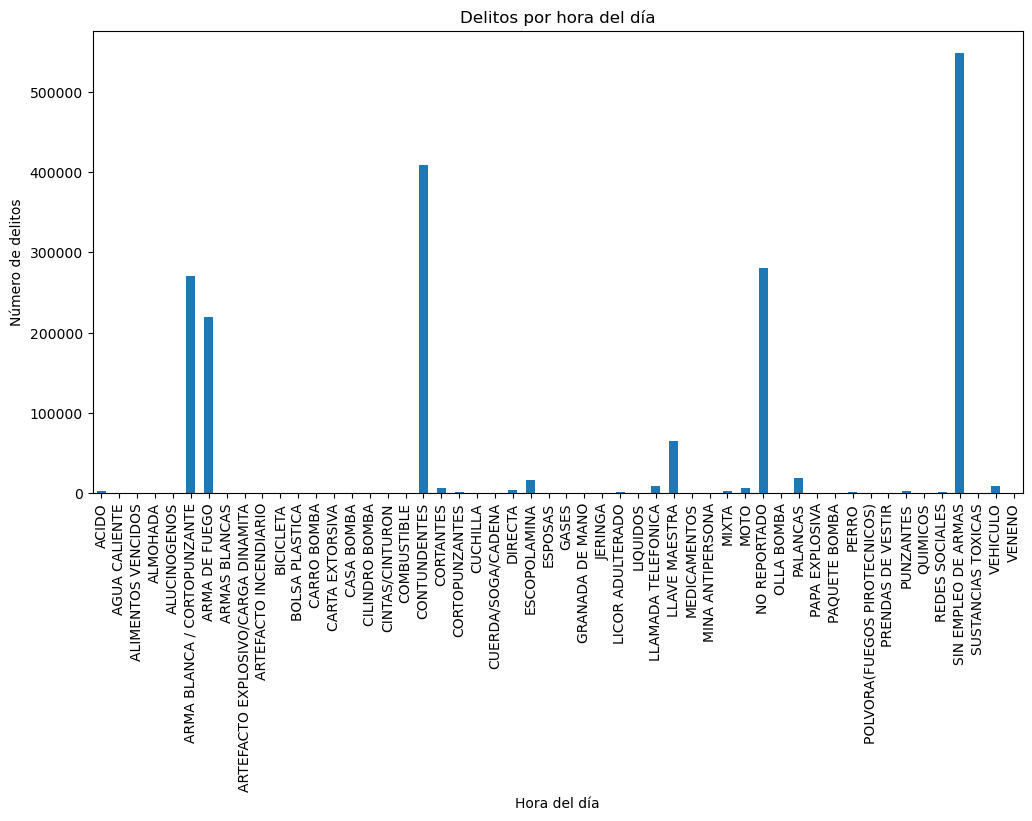

In [41]:
df['ARMAS MEDIOS'].value_counts().sort_index().plot(kind='bar', figsize=(12,6))
plt.title('Delitos por hora del día')
plt.xlabel('Hora del día')
plt.ylabel('Número de delitos')
plt.show()

In [42]:
df['GENERO'].value_counts()

GENERO
MASCULINO       840053
FEMENINO        795996
NO REPORTA        1144
NO REGISTRA         30
NO REPORTADO         2
Name: count, dtype: int64

In [43]:
# Normalizar a mayúsculas y quitar espacios
df['GENERO'] = df['GENERO'].str.upper().str.strip()

# Reemplazar variantes de "NO REPORTADO"
df['GENERO'] = df['GENERO'].replace({
    'NO REPORTA': 'NO REPORTADO',
    'NO REGISTRA': 'NO REPORTADO',
    'NO_REPORTADO' : 'NO REPORTADO',
    'NO_REPORTADA' : 'NO REPORTADO',
    'NO_REPORTA' : 'NO REPORTADO',
    'NO REPORTAD' : 'NO REPORTADO',
    'no_reportado' : 'NO REPORTADO'
})
df['GENERO'].value_counts()


GENERO
MASCULINO       840053
FEMENINO        795996
NO REPORTADO      1176
Name: count, dtype: int64

In [44]:
(df.isnull().mean()*100).round()

DELITO                  0.0
MUNICIPIO               0.0
ARMAS MEDIOS            0.0
FECHA HECHO             0.0
GENERO                 13.0
AGRUPA EDAD PERSONA    24.0
CANTIDAD                0.0
dtype: float64

In [45]:
df['GENERO'].value_counts()

GENERO
MASCULINO       840053
FEMENINO        795996
NO REPORTADO      1176
Name: count, dtype: int64

In [46]:
df['AGRUPA EDAD PERSONA'].value_counts()

AGRUPA EDAD PERSONA
ADULTOS         1240549
ADOLESCENTES     110473
MENORES           69569
NO REPORTA           14
Name: count, dtype: int64

In [47]:
def _clean_txt(x):
    if pd.isna(x):
        return x  # deja NaN; lo manejamos luego
    # minúsculas
    x = x.lower()
    # elimina tildes
    x = ''.join(c for c in unicodedata.normalize('NFD', x)
                if unicodedata.category(c) != 'Mn')
    # reemplaza espacios y barras por _
    x = re.sub(r'[ /]+', '_', x)
    # colapsa guiones bajos duplicados y recorta
    x = re.sub(r'_+', '_', x).strip('_')
    return x

for col in ['GENERO', 'AGRUPA EDAD PERSONA']:
    # 1. normalizar texto
    df[col] = df[col].apply(_clean_txt)

# 2a. elige SOLO UNA de las siguientes líneas ------------------------

# Opción A · imputar con string "no_reporta"
df['GENERO'] = df['GENERO'].fillna('NO REPORTADO')
df['AGRUPA EDAD PERSONA'] = df['AGRUPA EDAD PERSONA'].fillna('NO REPORTADO')

# ---O---
# Opción B · mantener NaN y crear bandera
# df['GENERO_NULO'] = df['GENERO'].isna().astype(int)
# df['EDAD_NULO']   = df['AGRUPA EDAD PERSONA'].isna().astype(int)

# --------------------------------------------------------------------

# 3. cambiar a categoría ordenada (edad opcional)
df['GENERO'] = df['GENERO'].astype('category')

edad_cat = pd.CategoricalDtype(
    categories=['menores', 'adolescentes', 'adultos', 'NO REPORTADO'],
    ordered=True
)
df['AGRUPA EDAD PERSONA'] = df['AGRUPA EDAD PERSONA'].astype(edad_cat)

# ── comprobación rápida ─────────────────────────────────────────────
print(df[['GENERO', 'AGRUPA EDAD PERSONA']].isna().mean()*100)
print(df['GENERO'].value_counts(dropna=False))
print(df['AGRUPA EDAD PERSONA'].value_counts(dropna=False))


GENERO                 0.000000
AGRUPA EDAD PERSONA    0.000747
dtype: float64
GENERO
masculino       840053
femenino        795996
NO REPORTADO    236771
no_reportado      1176
Name: count, dtype: int64
AGRUPA EDAD PERSONA
adultos         1240549
NO REPORTADO     453391
adolescentes     110473
menores           69569
NaN                  14
Name: count, dtype: int64


In [48]:
# Normalizar a mayúsculas y quitar espacios
df['GENERO'] = df['GENERO'].str.upper().str.strip()

# Reemplazar variantes de "NO REPORTADO"
df['GENERO'] = df['GENERO'].replace({
    'NO REPORTA': 'NO REPORTADO',
    'NO REGISTRA': 'NO REPORTADO',
    'NO_REPORTADO' : 'NO REPORTADO',
    'NO_REPORTADA' : 'NO REPORTADO',
    'NO_REPORTA' : 'NO REPORTADO',
    'NO REPORTAD' : 'NO REPORTADO',
    'no_reportado' : 'NO REPORTADO'
})
print(df['GENERO'].value_counts())

(df.isnull().mean()*100).round()

GENERO
MASCULINO       840053
FEMENINO        795996
NO REPORTADO    237947
Name: count, dtype: int64


DELITO                 0.0
MUNICIPIO              0.0
ARMAS MEDIOS           0.0
FECHA HECHO            0.0
GENERO                 0.0
AGRUPA EDAD PERSONA    0.0
CANTIDAD               0.0
dtype: float64

In [49]:
df.index

RangeIndex(start=0, stop=1873996, step=1)

In [52]:
df['DELITO'].value_counts()

DELITO
hurto_a_personas                       511417
lesiones_personales                    281541
violencia_intrafamiliar                228290
lesiones_en_accidente_de_transito      170824
hurto_a_comercio                       134124
amenazas                               126400
hurto_a_residencias                    120910
hurto_motocicletas                      99836
delitos_sexuales                        82989
hurto_automotores                       41793
homicidios                              37122
homicidios_en_accidente_de_transito     17477
extorsion                               14484
abigeato                                 4118
hurto_a_entidades_financieras            1063
secuestro                                 817
pirateria_terrestre                       791
Name: count, dtype: int64

In [53]:
# Filtrar solo los delitos que contienen la palabra 'hurto' o 'abigeato'
df = df[df['DELITO'].str.contains('hurto|abigeato', case=False, regex=True)]
df['DELITO'].value_counts()


DELITO
hurto_a_personas                 511417
hurto_a_comercio                 134124
hurto_a_residencias              120910
hurto_motocicletas                99836
hurto_automotores                 41793
abigeato                           4118
hurto_a_entidades_financieras      1063
Name: count, dtype: int64

In [54]:
# Filtrar el DataFrame entre 2010-01-01 y 2019-12-31
df = df.loc[(df['FECHA HECHO'] >= '2011-01-01') & (df['FECHA HECHO'] <= '2018-12-31')]

In [55]:
# Guardar el dataset en un archivo CSV
df.to_csv('delitos_limpios_2011_2018_hurto.csv', index=False)

In [ ]:
df.columns

Index(['DELITO', 'MUNICIPIO', 'ARMAS MEDIOS', 'FECHA HECHO', 'GENERO',
       'AGRUPA EDAD PERSONA', 'CANTIDAD'],
      dtype='object')